# YOLO segmentation + tracking on DAVIS 2017 val


Runs an Ultralytics YOLO segmentatio model with its built-in tracker on every frame of each DAVIS val video.
Uses the first-frame ground-truth mask only to pick which YOLO track is which DAVIS object (highest mask IoU, Hungarian matching).
Follows those tracks through the video. If a track is lost, it optionally recovers by picking the detection that best overlaps the object's last known mask.

- YOLO only knows the 80 COCO classes (person, bicycle, horse, dog, ...). DAVIS objects outside those (camel, swan → maybe "bird", kite, ...) can be missed, which counts as J = 0 for that object.
- This is a baseline, not the official DAVIS protocol. Metrics are unofficial (same code as the DINOv2 notebook, so the two are comparable).



In [2]:
# Cell 1: install
!pip install -q ultralytics

In [3]:
# Cell 2: config
import glob, os, math, time, json, subprocess
import numpy as np, pandas as pd
import torch
from PIL import Image, ImageDraw
from scipy import ndimage
from scipy.optimize import linear_sum_assignment
from ultralytics import YOLO

DEVICE = 0 if torch.cuda.is_available() else "cpu"
MODEL = "yolo11m-seg.pt"      # n / s / m / l / x  (bigger = more accurate, slower)
TRACKER = "bytetrack.yaml"    # or "botsort.yaml"
CONF = 0.25                   # detection confidence threshold
IMGSZ = 640                   # YOLO inference size
MATCH_IOU = 0.1               # min IoU to match a GT object to a YOLO detection in frame 0
RECOVER = True                # re-find an object by mask overlap when its track is lost
RECOVER_IOU = 0.3             # min IoU with the object's last known mask for recovery
MAX_SEQS = 10              # None = all 30 val sequences; e.g. 5 for a quick test
SHOW = ["breakdance", "bmx-trees", "blackswan", "camel"]   # sequences to visualize
OUT_DIR = "/kaggle/working/davis_yolo"
DATA_DIR = "/kaggle/working/data"
DAVIS_URL = "https://data.vision.ee.ethz.ch/csergi/share/davis/DAVIS-2017-trainval-480p.zip"
os.makedirs(OUT_DIR, exist_ok=True)
print("device:", DEVICE, "| model:", MODEL)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
device: 0 | model: yolo11m-seg.pt


In [4]:
# Cell 3: find or download DAVIS
def find_davis_root():
    for base in ["/kaggle/input", DATA_DIR]:
        for pat in ["**/JPEGImages/480p", "**/JPEGImages"]:
            for hit in glob.glob(f"{base}/{pat}", recursive=True):
                root = hit.split("/JPEGImages")[0]
                if os.path.isdir(os.path.join(root, "Annotations")):
                    return root
    return None

root = find_davis_root()
if root is None:
    os.makedirs(DATA_DIR, exist_ok=True)
    zip_path = os.path.join(DATA_DIR, "davis.zip")
    print("Downloading DAVIS 2017 (~800 MB)...")
    subprocess.run(["wget", "-q", "-O", zip_path, DAVIS_URL], check=True)
    subprocess.run(["unzip", "-q", zip_path, "-d", DATA_DIR], check=True)
    os.remove(zip_path)
    root = find_davis_root()
assert root is not None, f"No DAVIS found in {DATA_DIR}"

res = "480p" if os.path.isdir(os.path.join(root, "JPEGImages", "480p")) else ""
img_root = os.path.join(root, "JPEGImages", res)
ann_root = os.path.join(root, "Annotations", res)
val_lst = os.path.join(root, "ImageSets", "2017", "val.txt")
seqs = ([s.strip() for s in open(val_lst) if s.strip()]
        if os.path.exists(val_lst) else sorted(os.listdir(img_root)))
if MAX_SEQS: seqs = seqs[:MAX_SEQS]
print("Using DAVIS at", root, "|", len(seqs), "sequences")

Using DAVIS at /kaggle/working/data/DAVIS | 10 sequences


In [5]:
# Cell 4: metrics (J = IoU, F = boundary F-measure), same as the DINOv2 notebook
def jaccard(pred, gt):
    union = np.logical_or(pred, gt).sum()
    return 1.0 if union == 0 else np.logical_and(pred, gt).sum() / union

def boundary_f(pred, gt, tol_ratio=0.008):
    if pred.sum() == 0 and gt.sum() == 0: return 1.0
    if pred.sum() == 0 or gt.sum() == 0: return 0.0
    tol = max(1, int(round(tol_ratio * math.hypot(*gt.shape))))
    bnd = lambda m: m ^ ndimage.binary_erosion(m, border_value=0)
    bp, bg = bnd(pred), bnd(gt)
    prec = (ndimage.distance_transform_edt(~bg)[bp] <= tol).mean() if bp.any() else 0.0
    rec = (ndimage.distance_transform_edt(~bp)[bg] <= tol).mean() if bg.any() else 0.0
    return 0.0 if prec + rec == 0 else 2 * prec * rec / (prec + rec)

def score_sequence(preds, gts, K):
    J, Fs = [], []
    for k in range(1, K + 1):                      # per object, frames 1..end
        for p, g in zip(preds[1:], gts[1:]):
            J.append(jaccard(p == k, g == k))
            Fs.append(boundary_f(p == k, g == k))
    return float(np.mean(J)), float(np.mean(Fs))

def mask_iou(a, b):
    u = np.logical_or(a, b).sum()
    return 0.0 if u == 0 else np.logical_and(a, b).sum() / u

In [6]:
# Cell 5: run YOLO-seg + tracker on one video, then turn tracks into DAVIS object masks
def yolo_sequence(frame_paths):
    """Returns, per frame, a list of detections: dict(id, cls, conf, mask[H,W] bool)."""
    model = YOLO(MODEL)                            # fresh model = fresh tracker state per video
    out = []
    for p in frame_paths:
        r = model.track(p, persist=True, tracker=TRACKER, conf=CONF, imgsz=IMGSZ,
                        retina_masks=True, verbose=False, device=DEVICE)[0]
        dets = []
        if r.masks is not None and r.boxes is not None and len(r.boxes):
            H, W = r.orig_shape
            ms = r.masks.data.cpu().numpy() > 0.5
            ids = r.boxes.id.int().cpu().tolist() if r.boxes.id is not None else [-1] * len(ms)
            cls = r.boxes.cls.int().cpu().tolist()
            conf = r.boxes.conf.cpu().tolist()
            for m, i, c, s in zip(ms, ids, cls, conf):
                if m.shape != (H, W):              # safety: resize mask to frame size
                    m = np.array(Image.fromarray(m.astype(np.uint8)).resize((W, H), Image.NEAREST)) > 0
                dets.append(dict(id=i, cls=c, conf=s, mask=m))
        out.append(dets)
    return out, model.names

def predict_masks(dets_per_frame, gt0, K, names):
    """Match GT objects to YOLO tracks in frame 0, then follow the tracks."""
    H, W = gt0.shape
    assign, matched_cls = {}, {}                   # object k -> track id / class name
    last = {k: gt0 == k for k in range(1, K + 1)}  # last known mask per object
    d0 = dets_per_frame[0]
    if d0:
        C = np.array([[mask_iou(gt0 == k, d["mask"]) for d in d0] for k in range(1, K + 1)])
        rows, cols = linear_sum_assignment(-C)    # best one-to-one matching by IoU
        for r_, c_ in zip(rows, cols):
            if C[r_, c_] >= MATCH_IOU:
                assign[int(r_) + 1] = d0[c_]["id"]
                matched_cls[int(r_) + 1] = names[d0[c_]["cls"]]
    preds = []
    for t, dets in enumerate(dets_per_frame):
        if t == 0:
            preds.append(gt0.astype(np.uint8).copy())   # frame 0 is given, not scored
            continue
        lab, used = np.zeros((H, W), np.uint8), set()
        for k in range(1, K + 1):
            m, tid = None, assign.get(k)
            if tid is not None and tid != -1:
                hit = [i for i, d in enumerate(dets) if d["id"] == tid and i not in used]
                if hit:
                    m = dets[hit[0]]["mask"]; used.add(hit[0])
            if m is None and RECOVER and dets:
                cands = [(mask_iou(last[k], d["mask"]), i) for i, d in enumerate(dets) if i not in used]
                if cands:
                    s, i = max(cands)
                    if s >= RECOVER_IOU:
                        m = dets[i]["mask"]; used.add(i)
                        if dets[i]["id"] != -1: assign[k] = dets[i]["id"]
                        matched_cls.setdefault(k, names[dets[i]["cls"]])
            if m is not None:
                lab[m & (lab == 0)] = k
                last[k] = m
        preds.append(lab)
    return preds, matched_cls

In [7]:
# Cell 6: benchmark on DAVIS 2017 val
rows, raw = [], {}
for name in seqs:
    t0 = time.time()
    img_dir, ann_dir = os.path.join(img_root, name), os.path.join(ann_root, name)
    frame_names = sorted(os.listdir(img_dir))
    paths = [os.path.join(img_dir, n) for n in frame_names]
    gts = [np.array(Image.open(os.path.join(ann_dir, n[:-4] + ".png"))) for n in frame_names]
    K = int(gts[0].max())

    dets, names = yolo_sequence(paths)
    preds, matched_cls = predict_masks(dets, gts[0], K, names)
    J, Fb = score_sequence(preds, gts, K)

    seq_out = os.path.join(OUT_DIR, name); os.makedirs(seq_out, exist_ok=True)
    for n, m in zip(frame_names, preds):
        Image.fromarray(m).save(os.path.join(seq_out, n[:-4] + ".png"))
    if name in SHOW:
        raw[name] = dets                           # keep raw detections only for visualized videos

    rows.append(dict(seq=name, J=J, F=Fb, JF=(J + Fb) / 2, objects=K,
                     matched=f"{len(matched_cls)}/{K}",
                     yolo_classes=", ".join(f"{k}:{c}" for k, c in sorted(matched_cls.items())),
                     seconds=round(time.time() - t0, 1)))
    print(f"{name:20s} J={J:.3f} F={Fb:.3f} J&F={(J + Fb) / 2:.3f} | matched {len(matched_cls)}/{K} "
          f"[{rows[-1]['yolo_classes']}] ({rows[-1]['seconds']}s, {len(paths)} frames)")

df = pd.DataFrame(rows).set_index("seq")
df.to_csv(os.path.join(OUT_DIR, "scores.csv"))
print(f"\nYOLO ({MODEL}) on DAVIS 2017 val ({len(df)} sequences): "
      f"J={df.J.mean():.3f}  F={df.F.mean():.3f}  J&F={df.JF.mean():.3f}")
print(f"Objects matched in frame 0 (or recovered): {sum(int(m.split('/')[0]) for m in df.matched)}"
      f"/{df.objects.sum()}")

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 839ms
Prepared 1 package in 299ms
Installed 1 package in 2ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 1.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

bike-packing         J=0.670 F=0.633 J&F=0.652 | matched 2/2 [1:bicycle, 2:person] (22.7s, 69 frames)
blackswan            J=0.921 F=0.968 J&F=0.945 | matched 1/1 [1:bird] (4.4s, 50 frames)
bmx-trees            J=0.451 F=0.659 J&F=0.555 | matched 2/2 [1:bicycle, 2:person] (7.1s, 80 frames)
breakdance           J=0.811 F=0.822 J&F=0.816 | matched 1/1 [1:person] (7.2s, 84 frames)
camel                J=0.905 F=0.962 J&F=0.933 | matched 1/1 [1:horse] (7.4s, 90 frames)
car-roundabout       J=0.968 F=0.970 J&F=0.969 | matched 1/1 [1:car] (6.4s, 75 frames)
car-shadow           J=0.943 F=0.964 J&F=0.953 | matched 1/1 [1:car] (3.7s, 40 frames

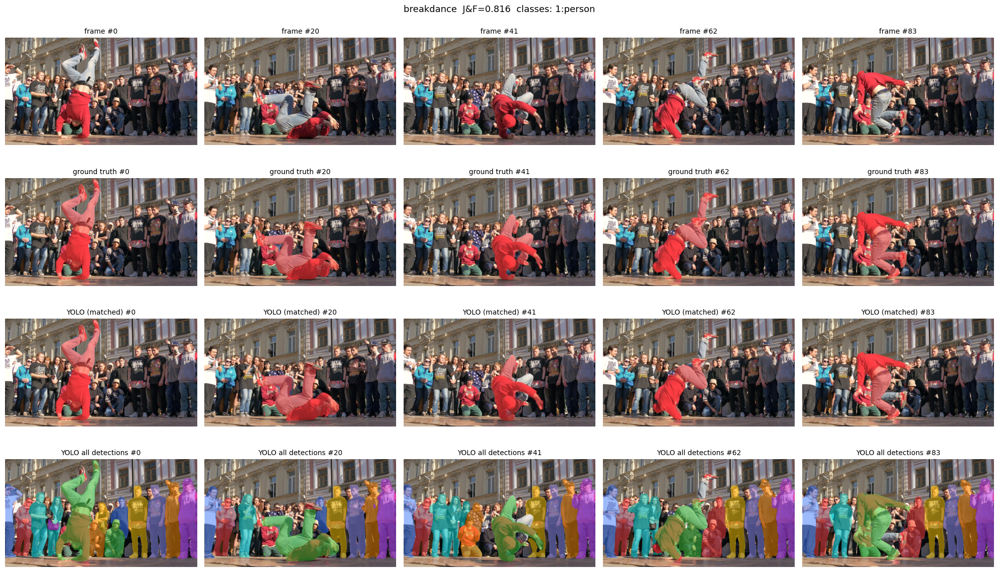

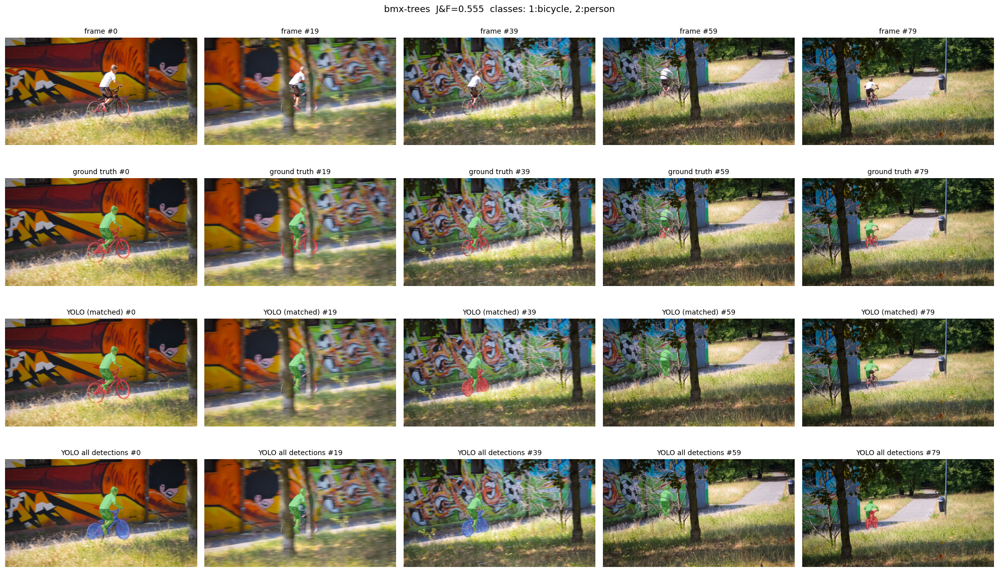

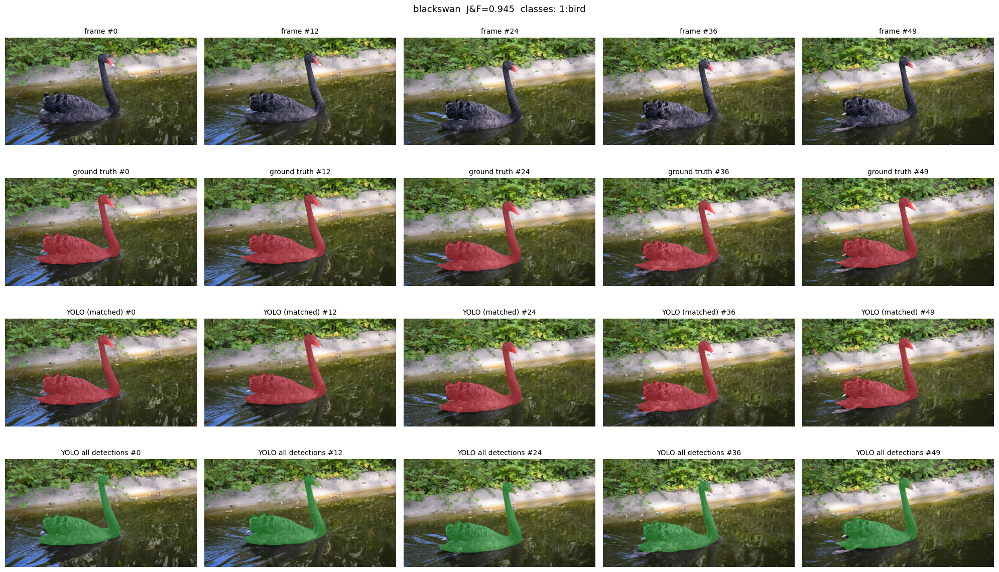

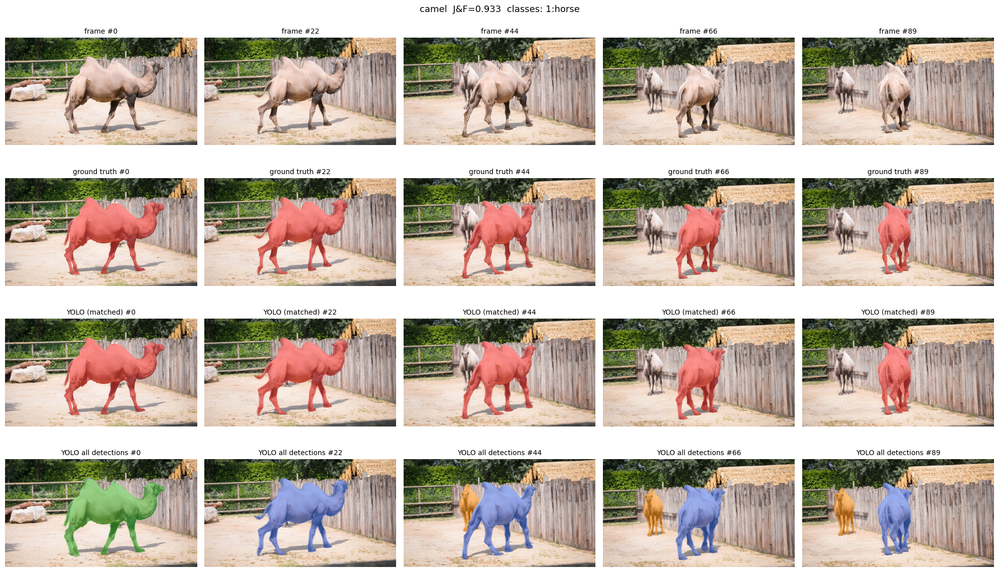

In [8]:
# Cell 7: visualize ground truth vs YOLO (matched objects) vs all raw YOLO detections
import matplotlib.pyplot as plt
PAL = np.array([[0,0,0],[255,60,60],[60,200,60],[60,120,255],[255,200,0],[200,60,255],
                [0,220,220],[255,140,0],[150,150,255]], np.uint8)

def overlay(img, lab, a=0.5):
    rgb = np.asarray(img).astype(np.float32)
    col = PAL[np.clip(lab, 0, len(PAL) - 1)].astype(np.float32)
    return np.where((lab > 0)[..., None], (1 - a) * rgb + a * col, rgb).astype(np.uint8)

def raw_label_map(dets, shape):
    lab = np.zeros(shape, np.uint8)
    for j, d in enumerate(sorted(dets, key=lambda d: -d["conf"])):
        lab[d["mask"] & (lab == 0)] = 1 + (d["id"] if d["id"] >= 0 else j) % (len(PAL) - 1)
    return lab

def show_sequence(name, n_frames=5):
    img_dir = os.path.join(img_root, name)
    frame_names = sorted(os.listdir(img_dir))
    picks = np.linspace(0, len(frame_names) - 1, n_frames).astype(int)
    has_raw = name in raw
    nrows = 3 + int(has_raw)
    fig, axes = plt.subplots(nrows, n_frames, figsize=(4 * n_frames, 3 * nrows))
    for c, i in enumerate(picks):
        n = frame_names[i][:-4]
        img = Image.open(os.path.join(img_dir, frame_names[i])).convert("RGB")
        gt = np.array(Image.open(os.path.join(ann_root, name, n + ".png")))
        pr = np.array(Image.open(os.path.join(OUT_DIR, name, n + ".png")))
        panels = [(np.asarray(img), "frame"), (overlay(img, gt), "ground truth"),
                  (overlay(img, pr), "YOLO (matched)")]
        if has_raw:
            panels.append((overlay(img, raw_label_map(raw[name][i], gt.shape)), "YOLO all detections"))
        for r, (im, title) in enumerate(panels):
            axes[r, c].imshow(im); axes[r, c].axis("off")
            axes[r, c].set_title(f"{title} #{i}", fontsize=10)
    plt.suptitle(f"{name}  J&F={df.loc[name, 'JF']:.3f}  classes: {df.loc[name, 'yolo_classes']}", fontsize=13)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"{name}_grid.png"), dpi=100); plt.show()

for name in SHOW:
    if name in df.index: show_sequence(name)

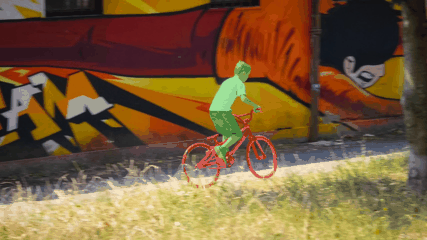

In [9]:
# Cell 8: GIF of the YOLO prediction for one video
from IPython.display import Image as IPImage, display

def make_gif(name, fps=10, width=427):
    img_dir = os.path.join(img_root, name)
    frames = []
    for f in sorted(os.listdir(img_dir)):
        img = Image.open(os.path.join(img_dir, f)).convert("RGB")
        pr = np.array(Image.open(os.path.join(OUT_DIR, name, f[:-4] + ".png")))
        im = Image.fromarray(overlay(img, pr))
        frames.append(im.resize((width, int(im.height * width / im.width))))
    path = os.path.join(OUT_DIR, f"{name}_yolo.gif")
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=int(1000 / fps), loop=0)
    display(IPImage(filename=path))

make_gif("bmx-trees")

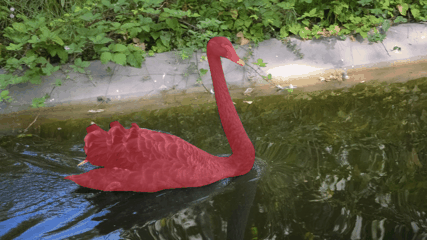

In [10]:
# Cell 8: GIF of the YOLO prediction for one video
from IPython.display import Image as IPImage, display

def make_gif(name, fps=10, width=427):
    img_dir = os.path.join(img_root, name)
    frames = []
    for f in sorted(os.listdir(img_dir)):
        img = Image.open(os.path.join(img_dir, f)).convert("RGB")
        pr = np.array(Image.open(os.path.join(OUT_DIR, name, f[:-4] + ".png")))
        im = Image.fromarray(overlay(img, pr))
        frames.append(im.resize((width, int(im.height * width / im.width))))
    path = os.path.join(OUT_DIR, f"{name}_yolo.gif")
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=int(1000 / fps), loop=0)
    display(IPImage(filename=path))

make_gif("blackswan")

In [12]:
# Cell 9: compare with the DINOv2 label-propagation results, if they exist in this session
hits = (glob.glob("/kaggle/working/davis_dinov2/scores.json") +
        glob.glob("/kaggle/input/**/davis_dinov2/scores.json", recursive=True) +
        glob.glob("/kaggle/input/**/scores.json", recursive=True))
dino_path = next((h for h in hits if "yolo" not in h), None)

if dino_path:
    print("DINOv2 scores from:", dino_path)
    dino = pd.DataFrame(json.load(open(dino_path))).T[["JF"]].rename(columns={"JF": "JF_dinov2"})
    cmp_df = df[["JF", "yolo_classes"]].rename(columns={"JF": "JF_yolo"}).join(dino, how="inner")
    cmp_df["diff (yolo - dino)"] = cmp_df.JF_yolo - cmp_df.JF_dinov2
    display(cmp_df.round(3))
    print(f"Mean over {len(cmp_df)} shared sequences: YOLO {cmp_df.JF_yolo.mean():.3f} | "
          f"DINOv2 {cmp_df.JF_dinov2.mean():.3f}")
else:
    print("No DINOv2 scores.json found: attach the DINOv2 notebook output (Add Input → Your Work).")

DINOv2 scores from: /kaggle/input/notebooks/oliviabuhr/task-1/davis_dinov2/scores.json


,JF_yolo,yolo_classes,JF_dinov2,diff (yolo - dino)
seq,,,,
bike-packing,0.652,"1:bicycle, 2:person",0.808,-0.156
blackswan,0.945,1:bird,0.900,0.044
bmx-trees,0.555,"1:bicycle, 2:person",0.516,0.039
breakdance,0.816,1:person,0.881,-0.065
camel,0.933,1:horse,0.744,0.189
car-roundabout,0.969,1:car,0.848,0.121
car-shadow,0.953,1:car,0.878,0.075
cows,0.933,1:cow,0.841,0.092
dance-twirl,0.833,1:person,0.821,0.013


Mean over 10 shared sequences: YOLO 0.854 | DINOv2 0.797
